In [1]:
import pandas as pd
import numpy as np
import matplotlib as cm
import matplotlib.pyplot as plt
import json
import seaborn as sns
import ptitprince as pt
from scipy import stats

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
# feature importance arrays saved as string object, reloading them as numpy arrays
def load_array_col(df, col_name):
    df[col_name] = df[col_name].apply(lambda x: np.array(json.loads(x)).flatten())
    return df

experiment_training_results = pd.read_csv('/Users/marcomaluf/Desktop/Unfinished Projects/paper/methodology/experiment_training_results.csv')
experiment_training_results = experiment_training_results.drop(columns=['Unnamed: 0'])
array_cols = ['final_real_feature_importances_aggregated', 
              'final_spectral_feature_importances_aggregated']

for col in array_cols:
    experiment_training_results = load_array_col(experiment_training_results, col)

In [3]:
experiment_training_results.describe(include='all')

,final_real_train_losses,final_real_val_losses,final_real_val_auc_scores,final_real_test_loss_scores,final_real_test_auc_scores,final_real_feature_importances_aggregated,real_epochs_to_convergence,final_spectral_train_losses,final_spectral_val_losses,final_spectral_val_auc_scores,final_spectral_test_loss_scores,final_spectral_test_auc_scores,final_spectral_feature_importances_aggregated,spectral_epochs_to_convergence
count,20.000000,20.000000,20.000000,20.000000,20.000000,20,20.00000,20.000000,20.000000,20.000000,20.000000,20.000000,20,20.000000
unique,NaN,NaN,NaN,NaN,NaN,20,NaN,NaN,NaN,NaN,NaN,NaN,20,NaN
top,NaN,NaN,NaN,NaN,NaN,"[0.005707377922464064, 0.02658744434686124, 0....",NaN,NaN,NaN,NaN,NaN,NaN,"[0.012554704934240742, 0.0226455607400257, 0.1...",NaN
freq,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
mean,0.445048,0.461042,0.866011,0.464035,0.863736,NaN,57.10000,0.418805,0.447917,0.875812,0.457793,0.870840,NaN,57.150000
std,0.034441,0.014619,0.008511,0.017666,0.010909,NaN,17.17066,0.045366,0.017398,0.009015,0.025992,0.011299,NaN,11.426078
min,0.399908,0.439197,0.852732,0.434804,0.842077,NaN,36.00000,0.350749,0.414815,0.863890,0.410982,0.849946,NaN,36.000000
25%,0.422012,0.452793,0.861062,0.450648,0.853577,NaN,42.75000,0.382445,0.436385,0.868663,0.438803,0.863396,NaN,49.250000
50%,0.438075,0.459840,0.865463,0.465347,0.864340,NaN,53.00000,0.411182,0.448735,0.875511,0.461969,0.869806,NaN,57.500000
75%,0.474861,0.466291,0.871144,0.475744,0.871095,NaN,69.75000,0.455548,0.462413,0.883837,0.469529,0.879442,NaN,66.000000


## <center>What question(s) am I trying to answer with this data?<center>

The main question of my entire time working in this is: **is using the spectral embeddings over the real positional data better?**

With this data, I can answer that question by:
- compare the results of each metric to each other for each model respectively (e.g. compare train loss for both). The simplest way is to take a graphical look at the distributions of the data, and do a hypothesis test between each metric for both models

- compare the time to converge (via the epochs)

- compare the feature importances! There are 2 tests I can do to compare:
    1. For both models, I compare the importances of the features that are shared between the 2; the null hypothesis is that they are essentially the same for both models. 
    2. Compare the spectral embedding features to their corresponding "real" features

The assumption is that the spectral embedding model performs at least the same, if not better, than the "real" model, and that the feature importances for the spectral features compared to the "real" features are also at least the same, if not better

------

## <center>Plan for Plotting and Analyzing Results<center>

- For each training/validation metric, make a raincloud plot, and then do a hypothesis test to test if there is any difference 
    - first test if the distributions are equal, and if they are not equal then see if the specral is less-than (or greater-then depending on the metric) 

- For the Epochs, make the simple line graph showing for each experiment run the epochs to convergence of both models, and also report the mean and variance

- For the feature importances, figure out a way to do the 2 types of comparisons I listed above (look back at the chat in Claude for ideas)

In [4]:
def make_raincloud_plot(df, data1, data2):
    df_long = df[[data1,data2]].melt(var_name='variable', value_name='value')
    fig, ax = plt.subplots(figsize=(8, 4))

    pt.RainCloud(
        x='variable',
        y='value',
        data=df_long,
        palette='Spectral',
        bw=0.13,
        width_viol=0.5,
        ax=ax,
        orient='h',
        point_size=4
    )

    plt.tight_layout()
    plt.show()

## <center>Training/Testing Metrics<center>

_**<center>NEW PLAN:<center>**_

For each metric, first perform a 2-sample Cramer-von-Mises test to test whether the two samples come from the same distribution. Then, perform a Mann-Whitney U test in both the less than and greater than directions to test whether performance is better/worse for each metric.

Cramer-von-Mises test was chosen over a Kolmogorov-Smirnov test due to KS requiring a larger sample size for greater statistical power. 

Mann-Whitney U tests were chosen as a way to test the characteristics of the differences between the data.

### **Final Training Losses:**

#### Graphical and Tabular exploration of the Data

/opt/anaconda3/lib/python3.12/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


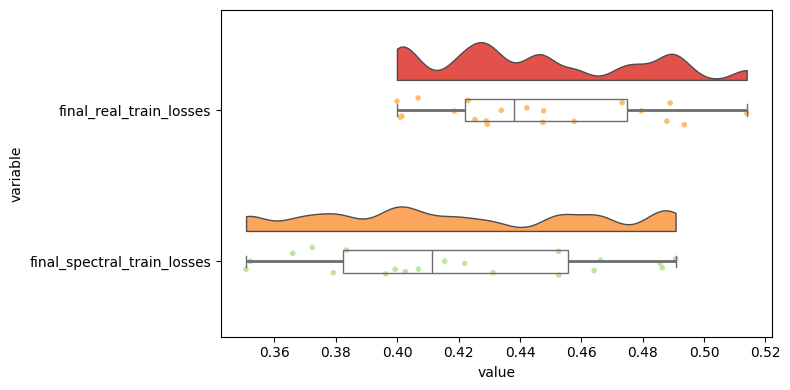

In [5]:
make_raincloud_plot(experiment_training_results, 'final_real_train_losses', 'final_spectral_train_losses')

In [6]:
experiment_training_results[['final_real_train_losses', 'final_spectral_train_losses']].describe()

,final_real_train_losses,final_spectral_train_losses
count,20.000000,20.000000
mean,0.445048,0.418805
std,0.034441,0.045366
min,0.399908,0.350749
25%,0.422012,0.382445
50%,0.438075,0.411182
75%,0.474861,0.455548
max,0.513874,0.490702


Both the mean and median traing loss of the spectral model are less than the real model, as well as each quartile for the spectral model being less than the real model. However, the spectral model has a higher slightly higher standard deviation. Looking at the raincloud plot, it appears that the distribution of the losses for the spectral model tends to be lower than that of the real model.

#### Test to see if the two samples come from the same underlying distribution

In [7]:
### H0: final_spectral_train_losses = final_real_train_losses

stats.cramervonmises_2samp(x=experiment_training_results['final_spectral_train_losses'],
                           y=experiment_training_results['final_real_train_losses'])

CramerVonMisesResult(statistic=0.4425000000000008, pvalue=0.057706104115157655)

With $\alpha = 0.05$, we fail to reject the null. However, there is significance under $\alpha = 0.1$, therefore there is a slight statistical siginficance that the train losses are do not come from the same distribution.

#### Test to see if the spectral model performs better than the real model

In [8]:
### H0: final_spectral_train_losses <= final_real_train_losses

stats.mannwhitneyu(x=experiment_training_results['final_spectral_train_losses'],
                   y=experiment_training_results['final_real_train_losses'],
                   alternative='greater')

MannwhitneyuResult(statistic=129.0, pvalue=0.9734484377201134)

Due to the high p-value, we fail to reject the null hypothesis that the spectral loss is less than or equal to the real loss.

#### Test to see if the spectral model performs worse than the real model

In [9]:
### H0: final_spectral_train_losses >= final_real_train_losses

stats.mannwhitneyu(x=experiment_training_results['final_spectral_train_losses'],
                   y=experiment_training_results['final_real_train_losses'],
                   alternative='less')

MannwhitneyuResult(statistic=129.0, pvalue=0.028258268683980944)

Under the $\alpha = 0.05$ level, there we reject the null hypothesis in favor of the alternate that final_spectral_train_losses < final_real_train_losses, which shows statistical significance that the spectral model achieves a lower training loss than the real model.

#### Conclusion:

The results from the tests confirm the assumption from the graphical and tabular analysis that the spectral model performs better than the real model under the metric of training loss.

### **Final Validation Losses:**

#### Graphical and Tabular exploration of the Data

/opt/anaconda3/lib/python3.12/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


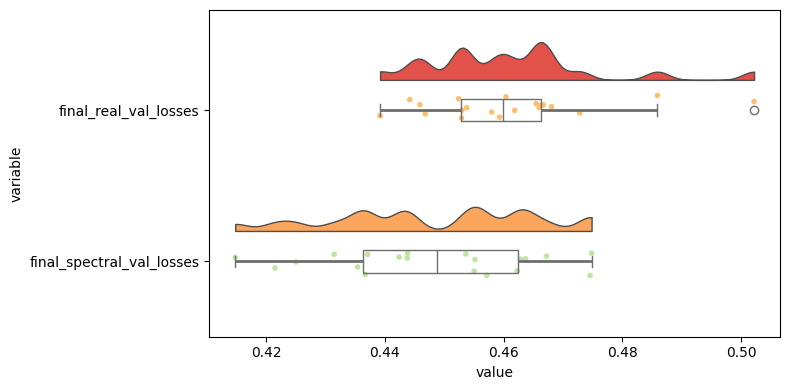

In [10]:
make_raincloud_plot(experiment_training_results, 'final_real_val_losses', 'final_spectral_val_losses')

In [11]:
experiment_training_results[['final_real_val_losses', 'final_spectral_val_losses']].describe()

,final_real_val_losses,final_spectral_val_losses
count,20.000000,20.000000
mean,0.461042,0.447917
std,0.014619,0.017398
min,0.439197,0.414815
25%,0.452793,0.436385
50%,0.459840,0.448735
75%,0.466291,0.462413
max,0.502148,0.474798


The mean training loss for the spectral model is less than that of the real model, as well as all the quartiles. However, the standard deviation is slightly higher for the spectral model than the real model (by less than 0.003). Looking at the raincloud plot, it appears that the distribution of the spectral validation losses tends to be lower than that of the real model.

#### Test to see if the two samples come from the same underlying distribution

In [12]:
### H0: final_spectral_val_losses = final_real_val_losses

stats.cramervonmises_2samp(x=experiment_training_results['final_spectral_val_losses'],
                           y=experiment_training_results['final_real_val_losses'])

CramerVonMisesResult(statistic=0.5100000000000007, pvalue=0.038351055418328235)

With $\alpha = 0.05$, we reject the null hypothesis that the distributions are equal in favor of the alternative hypothesis that they are not equal.

#### Test to see if the spectral model performs better than the real model

In [13]:
### H0: final_spectral_val_losses <= final_real_val_losses

stats.mannwhitneyu(x=experiment_training_results['final_spectral_val_losses'],
                   y=experiment_training_results['final_real_val_losses'],
                   alternative='greater')

MannwhitneyuResult(statistic=122.0, pvalue=0.9831411655315684)

Due to the high p-value, we fail to reject the null hypothesis that the spectral validation losses are less than or equal to the real validation losses.

#### Test to see if the spectral model performs worse than the real model

In [14]:
### H0: final_spectral_val_losses >= final_real_val_losses

stats.mannwhitneyu(x=experiment_training_results['final_spectral_val_losses'],
                   y=experiment_training_results['final_real_val_losses'],
                   alternative='less')

MannwhitneyuResult(statistic=122.0, pvalue=0.01802416333209157)

At the $\alpha = 0.05$ level, we reject the null hypothesis that final_spectral_val_losses >= final_real_val_losses in favor of the alternate hypothesis that final_spectral_val_losses < final_real_val_losses, showing statistical significance that the spectral model achieves a lower validation loss than the real model.

#### Conclusion

The results from the tests confirm the assumption from the graphical and tabular analysis that the spectral model performs better than the real model under the metric of validation loss.

### **Final Validation AUC Scores:**

#### Graphical and Tabular exploration of the Data

/opt/anaconda3/lib/python3.12/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


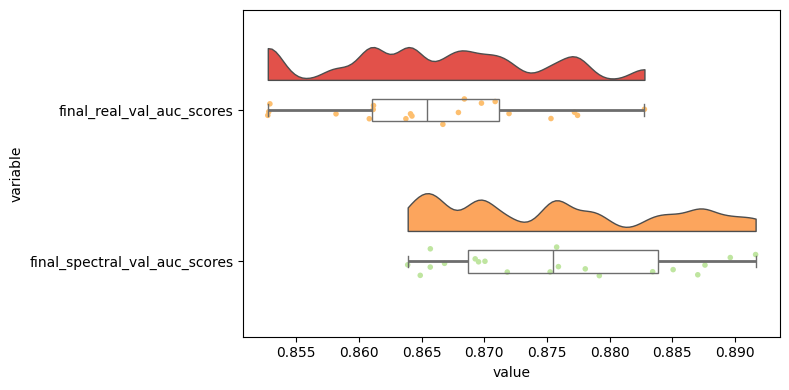

In [15]:
make_raincloud_plot(experiment_training_results, 'final_real_val_auc_scores', 'final_spectral_val_auc_scores')

In [16]:
experiment_training_results[['final_real_val_auc_scores', 'final_spectral_val_auc_scores']].describe()

,final_real_val_auc_scores,final_spectral_val_auc_scores
count,20.000000,20.000000
mean,0.866011,0.875812
std,0.008511,0.009015
min,0.852732,0.863890
25%,0.861062,0.868663
50%,0.865463,0.875511
75%,0.871144,0.883837
max,0.882772,0.891640


The mean auc score for the specral model is higher than that of the real model, as well ass all of the quartiles. However, the standard deviation of the spectral model is ever so slightly higher (but only by 0.0005). Looking at the raincloud plot, it appears that the distribution of the validation AUC scores of the spectral model tends to be greater than that of the real model.

#### Test to see if the two samples come from the same underlying distribution

In [17]:
### H0: final_spectral_val_auc_scores = final_real_val_auc_scores

stats.cramervonmises_2samp(x=experiment_training_results['final_spectral_val_auc_scores'],
                           y=experiment_training_results['final_real_val_auc_scores'])

CramerVonMisesResult(statistic=0.8950000000000005, pvalue=0.0039181747456642265)

Under the $\alpha = 0.05$ level, we reject the null hypothesis that the distributions are equal.

#### Test to see if the spectral model performs better than the real model

In [18]:
### H0: final_spectral_val_auc_scores <= final_real_val_auc_scores

stats.mannwhitneyu(x=experiment_training_results['final_spectral_val_auc_scores'],
                   y=experiment_training_results['final_real_val_auc_scores'],
                   alternative='greater')

MannwhitneyuResult(statistic=312.0, pvalue=0.0012803076435722934)

Under the $\alpha = 0.05$ level, we reject the null hypothesis that final_spectral_val_auc_scores <= final_real_val_auc_scores in favor of the alternative hypothesis that final_spectral_val_auc_scores > final_real_val_auc_scores.

#### Test to see if the spectral model performs worse than the real model

In [19]:
### H0: final_spectral_val_auc_scores >= final_real_val_auc_scores

stats.mannwhitneyu(x=experiment_training_results['final_spectral_val_auc_scores'],
                   y=experiment_training_results['final_real_val_auc_scores'],
                   alternative='less')

MannwhitneyuResult(statistic=312.0, pvalue=0.9988293636962532)

Due to the high p-value, we fail to reject the null hypothesis that final_spectral_val_auc_scores >= final_real_val_auc_scores.

#### Conclusion

The results from the tests confirm the assumption from the graphical and tabular analysis that the spectral model performs better than the real model under the metric of validation AUC.

### **Final Test Losses:**

#### Graphical and Tabular Exploration of the Data

/opt/anaconda3/lib/python3.12/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


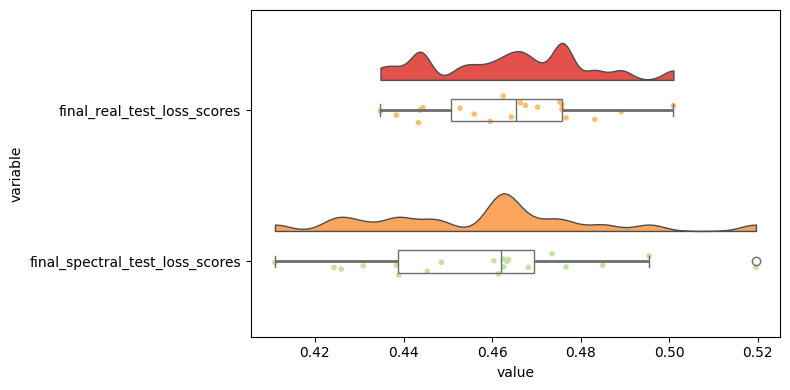

In [20]:
make_raincloud_plot(experiment_training_results, 'final_real_test_loss_scores', 'final_spectral_test_loss_scores')

In [21]:
experiment_training_results[['final_real_test_loss_scores', 'final_spectral_test_loss_scores']].describe()

,final_real_test_loss_scores,final_spectral_test_loss_scores
count,20.000000,20.000000
mean,0.464035,0.457793
std,0.017666,0.025992
min,0.434804,0.410982
25%,0.450648,0.438803
50%,0.465347,0.461969
75%,0.475744,0.469529
max,0.500929,0.519558


The mean loss of the spectral model is less than that of the real model, as well as all of the quartiles *except* for the max value. The standard deviation for the spectral model is higher than that of the real model. Looking at the raincloud plot, the distribution of the test losses for the spectral model cover a wider range than that of the real model. Without counting the outlier, however, the distribution of the spectral model appears to slightly tend lower than that of the real model.

#### Test to see if the two samples come from the same underlying distribution

In [22]:
### H0: final_spectral_test_loss_scores = final_real_test_loss_scores

stats.cramervonmises_2samp(x=experiment_training_results['final_spectral_test_loss_scores'],
                           y=experiment_training_results['final_real_test_loss_scores'])

CramerVonMisesResult(statistic=0.13750000000000018, pvalue=0.4515265479863826)

Due to the high p-value, we fail to reject the null hypothesis that the distributions are equal.

#### Test to see if the spectral model performs better than the real model

In [23]:
### H0: final_spectral_test_loss_scores <= final_real_test_loss_scores

stats.mannwhitneyu(x=experiment_training_results['final_spectral_test_loss_scores'],
                   y=experiment_training_results['final_real_test_loss_scores'],
                   alternative='greater')

MannwhitneyuResult(statistic=164.0, pvalue=0.8382591270391544)

Due to the high p-value, we fail to reject the null hypothesis that final_spectral_test_loss_scores <= final_real_test_loss_scores.

#### Test to see if the spectral model performs worse than the real model

In [24]:
### H0: final_spectral_test_loss_scores >= final_real_test_loss_scores

stats.mannwhitneyu(x=experiment_training_results['final_spectral_test_loss_scores'],
                   y=experiment_training_results['final_real_test_loss_scores'],
                   alternative='less')

MannwhitneyuResult(statistic=164.0, pvalue=0.16845761919115998)

Due to the high p-value, we fail to reject the null hypothesis that final_spectral_test_loss_scores >= final_real_test_loss_scores.

#### Conclusion

The results of the tests do not show that there is any statistically significant difference between the distributions. In other words, there is no statistically significant difference between the models when it comes to the test loss.

### **Final Test AUC Scores:**

#### Graphical and Tabular Exploration of the Data

/opt/anaconda3/lib/python3.12/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


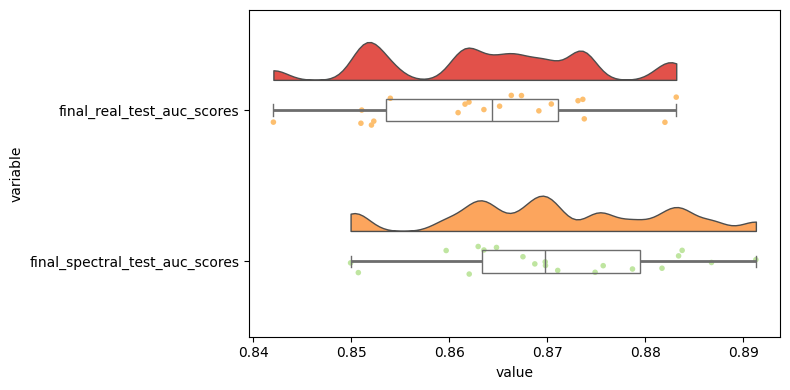

In [25]:
make_raincloud_plot(experiment_training_results, 'final_real_test_auc_scores', 'final_spectral_test_auc_scores')

In [26]:
experiment_training_results[['final_real_test_auc_scores', 'final_spectral_test_auc_scores']].describe()

,final_real_test_auc_scores,final_spectral_test_auc_scores
count,20.000000,20.000000
mean,0.863736,0.870840
std,0.010909,0.011299
min,0.842077,0.849946
25%,0.853577,0.863396
50%,0.864340,0.869806
75%,0.871095,0.879442
max,0.883150,0.891271


The mean AUC score for the spectral model is slightly higher than that of the real model, as well as all of the quartiles. However, the standard deviation of the spectral model is slightly higher than that of the real model (by ~0.001). Looking at the raincloud plot, it appears that the distribution of the AUC scores for the spectral model tend higher than that of the real model.

#### Test to see if the two samples come from the same underlying distribution

In [27]:
### H0: final_spectral_test_auc_scores = final_real_test_auc_scores

stats.cramervonmises_2samp(x=experiment_training_results['final_spectral_test_auc_scores'],
                           y=experiment_training_results['final_real_test_auc_scores'])

CramerVonMisesResult(statistic=0.35749999999999993, pvalue=0.09768851517170905)

Under the $\alpha = 0.05$ level, we fail to reject the null hypothesis that the distributions are equal. However, there is significance under the $\alpha = 0.1$ level, in which we reject the null hypothesis in favor of the alternative hypothesis.

#### Test to see if the spectral model performs better than the real model

In [28]:
### H0: final_spectral_test_auc_scores <= final_real_test_auc_scores

stats.mannwhitneyu(x=experiment_training_results['final_spectral_test_auc_scores'],
                   y=experiment_training_results['final_real_test_auc_scores'],
                   alternative='greater')

MannwhitneyuResult(statistic=267.0, pvalue=0.03602271523367194)

Under the $\alpha = 0.05$ level, we reject the null hypothesis that final_spectral_test_auc_scores <= final_real_test_auc_scores in favor of the alternate hypothesis that final_spectral_test_auc_scores > final_real_test_auc_scores.

#### Test to see if the spectral model performs worse than the real model

In [29]:
### H0: final_spectral_test_auc_scores >= final_real_test_auc_scores

stats.mannwhitneyu(x=experiment_training_results['final_spectral_test_auc_scores'],
                   y=experiment_training_results['final_real_test_auc_scores'],
                   alternative='less')

MannwhitneyuResult(statistic=267.0, pvalue=0.9660659063937578)

Due to the high p-value, we fail to reject the null hypothesis that final_spectral_test_auc_scores >= final_real_test_auc_scores.

#### Conclusion

The results from the tests confirm the assumption from the graphical and tabular analysis that the spectral model performs better than the real model under the metric of test AUC.

### **Epochs to converge:**

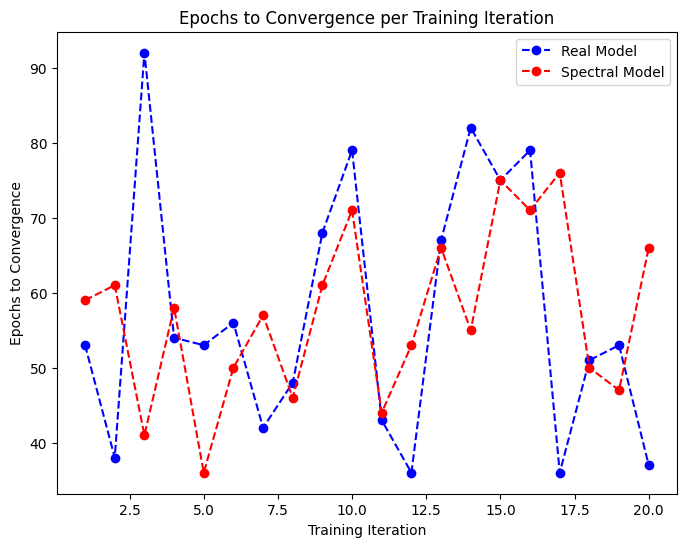

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(range(1,21), experiment_training_results['real_epochs_to_convergence'], 'o--b', label='Real Model')
ax.plot(range(1,21), experiment_training_results['spectral_epochs_to_convergence'], 'o--r', label='Spectral Model')
ax.set_title('Epochs to Convergence per Training Iteration')
ax.set_xlabel('Training Iteration')
ax.set_ylabel('Epochs to Convergence')
ax.legend()

plt.show()

### Observations:

- When looking at the visualizations (graphical and tabular) for each metric between the models, there is slight evidence showing that the spectral model can outperform the real model, however further analysis was needed to confirm any statistical significance.

- For the training and validation metrics, the tests showed that there is statistical significance showing that the spectral model outperforms the real model.

- For the testing metrics:
    - the testing on the test loss showed that there is no statistically significant difference in performance
    - the testing on the test AUC showed that there is a statistically significant difference in performance, showing that the spectral model outperforms the real model on unseen data when looking at the AUC score

- The time to converge in training (in terms of training iterations/epochs) appears to be relatively similar, with about a 50/50 split on if a model converged faster than the other (real model converged faster 9/20 times, spectral converged faster 10/20 times, and they tied once), suggesting that there is no real difference in training times. No statistical test was deemed necessary to confirm this.

## <center>Feature Importances<center>

_**<center>Main Question:<center>**_

<center> Are the spectral features just as, if not more, informative for predictions than their 'real units' counterparts? <center>

We have already shown in the prior tests on model performance metrics that, for this experiment, the spectral model outperforms the real model in all categories except for test loss (loss measured on unseen data) and training times (epochs until convergence). Answering this next question involves comparing the new features (the spectral embeddings) to the original features (the 'real' units) to see if the results of the statistical tests can be attributed to the design of the model, or if those were due to some random chance. Additionally, we want to see if the features that are shared between the two models show similar impacts on predictions, since we want to ensure that the only difference in predictions between the two models are only between the 'real' and the spectral features.

In [31]:
spectral_feature_importances = experiment_training_results['final_spectral_feature_importances_aggregated']
real_feature_importances = experiment_training_results['final_real_feature_importances_aggregated']

In [32]:
spectral_model_features = ['pos_x','pos_y','pos_z','speed','dist_to_goal','angle_to_goal',
                           'players_btwn_ball_and_goal','players_within_400_of_ball','ball_state',
                           'team1_cluster','team2_cluster','team1_dist_to_ball_state','team2_dist_to_ball_state']

real_model_features = ['pos_x','pos_y','pos_z','speed','dist_to_goal','angle_to_goal',
                       'players_btwn_ball_and_goal','players_within_400_of_ball','blue_x_centroid',
                       'blue_y_centroid','blue_z_centroid','blue_centroid_dist_to_ball','orange_x_centroid',
                       'orange_y_centroid','orange_z_centroid','orange_centroid_dist_to_ball']

spectral_feature_importances_df = pd.DataFrame(spectral_feature_importances.to_list(), columns=spectral_model_features)
real_feature_importances_df = pd.DataFrame(real_feature_importances.to_list(), columns=real_model_features)

### <center>Numerical and Graphical Exploration<center>

In [33]:
spectral_feature_importances_df.iloc[:,0:8].mean()

pos_x                         0.017023
pos_y                         0.037611
pos_z                         0.155532
speed                         0.015962
dist_to_goal                  0.302747
angle_to_goal                 0.159805
players_btwn_ball_and_goal    0.005223
players_within_400_of_ball    0.022751
dtype: float64

In [34]:
real_feature_importances_df.iloc[:,0:8].mean()

pos_x                         0.012951
pos_y                         0.025642
pos_z                         0.152796
speed                         0.014243
dist_to_goal                  0.269703
angle_to_goal                 0.138076
players_btwn_ball_and_goal    0.004042
players_within_400_of_ball    0.018504
dtype: float64

In [35]:
spectral_feature_importances_df.iloc[:,8:].mean()

ball_state                  0.011357
team1_cluster               0.033805
team2_cluster               0.036410
team1_dist_to_ball_state    0.032677
team2_dist_to_ball_state    0.033668
dtype: float64

In [36]:
real_feature_importances_df.iloc[:,8:].mean()

blue_x_centroid                 0.000318
blue_y_centroid                 0.000579
blue_z_centroid                 0.000173
blue_centroid_dist_to_ball      0.003606
orange_x_centroid               0.000445
orange_y_centroid               0.000538
orange_z_centroid               0.000439
orange_centroid_dist_to_ball    0.001638
dtype: float64

In [37]:
import matplotlib.gridspec as gridspec
from scipy.stats import gaussian_kde


def ridgeplot2(df1, df2=None, figsize=(14, None), overlap=0.0, cmap='viridis',
              bw_method=None, point_alpha=0.6, point_size=15,
              fill_alpha=0.6, x_label='Value', title=None, x_pad=0.05,
              col_titles=('Left', 'Right')):
    """
    Create a stacked KDE + scatter plot for each column of one or two DataFrames,
    displayed side by side (df1 left, df2 right), each independently x-scaled.
    Subplots are top-aligned; the shorter panel leaves blank space at the bottom.

    Parameters
    ----------
    df1 : pd.DataFrame
        Left panel — each column is a 1D variable.
    df2 : pd.DataFrame or None
        Right panel — optional. If None, only one panel is shown.
    figsize : tuple
        (width, height). Height is auto-scaled if None.
    overlap : float
        Vertical spacing between subplots (0 = no overlap).
    cmap : str
        Matplotlib colormap name.
    bw_method : str, float, or None
        Bandwidth for gaussian_kde.
    point_alpha, point_size : scatter styling.
    fill_alpha : KDE fill transparency.
    x_label : x-axis label shown on every subplot.
    title : optional overall figure title.
    x_pad : fractional x-range padding per subplot.
    col_titles : tuple of str
        Panel header labels, e.g. ('Real Features', 'Spectral Features').
    """
    dfs = [df1] if df2 is None else [df1, df2]
    n_panels = len(dfs)
    n_rows = [len(df.columns) for df in dfs]
    max_rows = max(n_rows)

    width, height = figsize
    if height is None:
        height = max(4, max_rows * 1.4)

    cmap_fn = plt.get_cmap(cmap)
    fig = plt.figure(figsize=(width, height))

    # single GridSpec: max_rows rows x n_panels columns
    gs = gridspec.GridSpec(
        max_rows, n_panels,
        figure=fig,
        hspace=0.6 + overlap,
        wspace=0.5,
        left=0.10,
        right=0.97,
        top=0.94,
        bottom=0.04,
    )

    for p, df in enumerate(dfs):
        cols = df.columns
        n = len(cols)
        colors = cmap_fn(np.linspace(0, 1, n))

        # panel title above row 0
        fig.text(
            0.10 + p * (0.87 / n_panels) + (0.87 / n_panels) / 2,
            0.97,
            col_titles[p],
            ha='center', va='top', fontsize=11, fontweight='bold'
        )

        for i, col in enumerate(cols):
            ax = fig.add_subplot(gs[i, p])   # row i, column p — top-aligned
            data = df[col].dropna().values
            color = colors[i]

            x_min, x_max = data.min(), data.max()
            pad = x_pad * (x_max - x_min) if x_max != x_min else 0.5
            x_grid = np.linspace(x_min - pad, x_max + pad, 500)

            # KDE
            if len(data) > 1:
                kde = gaussian_kde(data, bw_method=bw_method)
                y = kde(x_grid)
                y = y / y.max()
                ax.plot(x_grid, y, color=color, lw=1.5)
                ax.fill_between(x_grid, y, color=color, alpha=fill_alpha)

            # scatter with jitter along baseline
            jitter = np.random.uniform(0, 0.05, size=len(data))
            ax.scatter(data, jitter, color=color, alpha=point_alpha,
                       s=point_size, zorder=3)

            ax.set_xlim(x_min - pad, x_max + pad)
            ax.set_ylim(0, 1.2)
            ax.set_yticks([])
            ax.set_ylabel(col, rotation=0, ha='right', va='center', fontsize=9)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_visible(False)
            ax.tick_params(axis='x', labelsize=8)
            ax.set_xlabel(x_label, fontsize=8)

    if title:
        fig.suptitle(title, y=1.0, fontsize=13)

    return fig

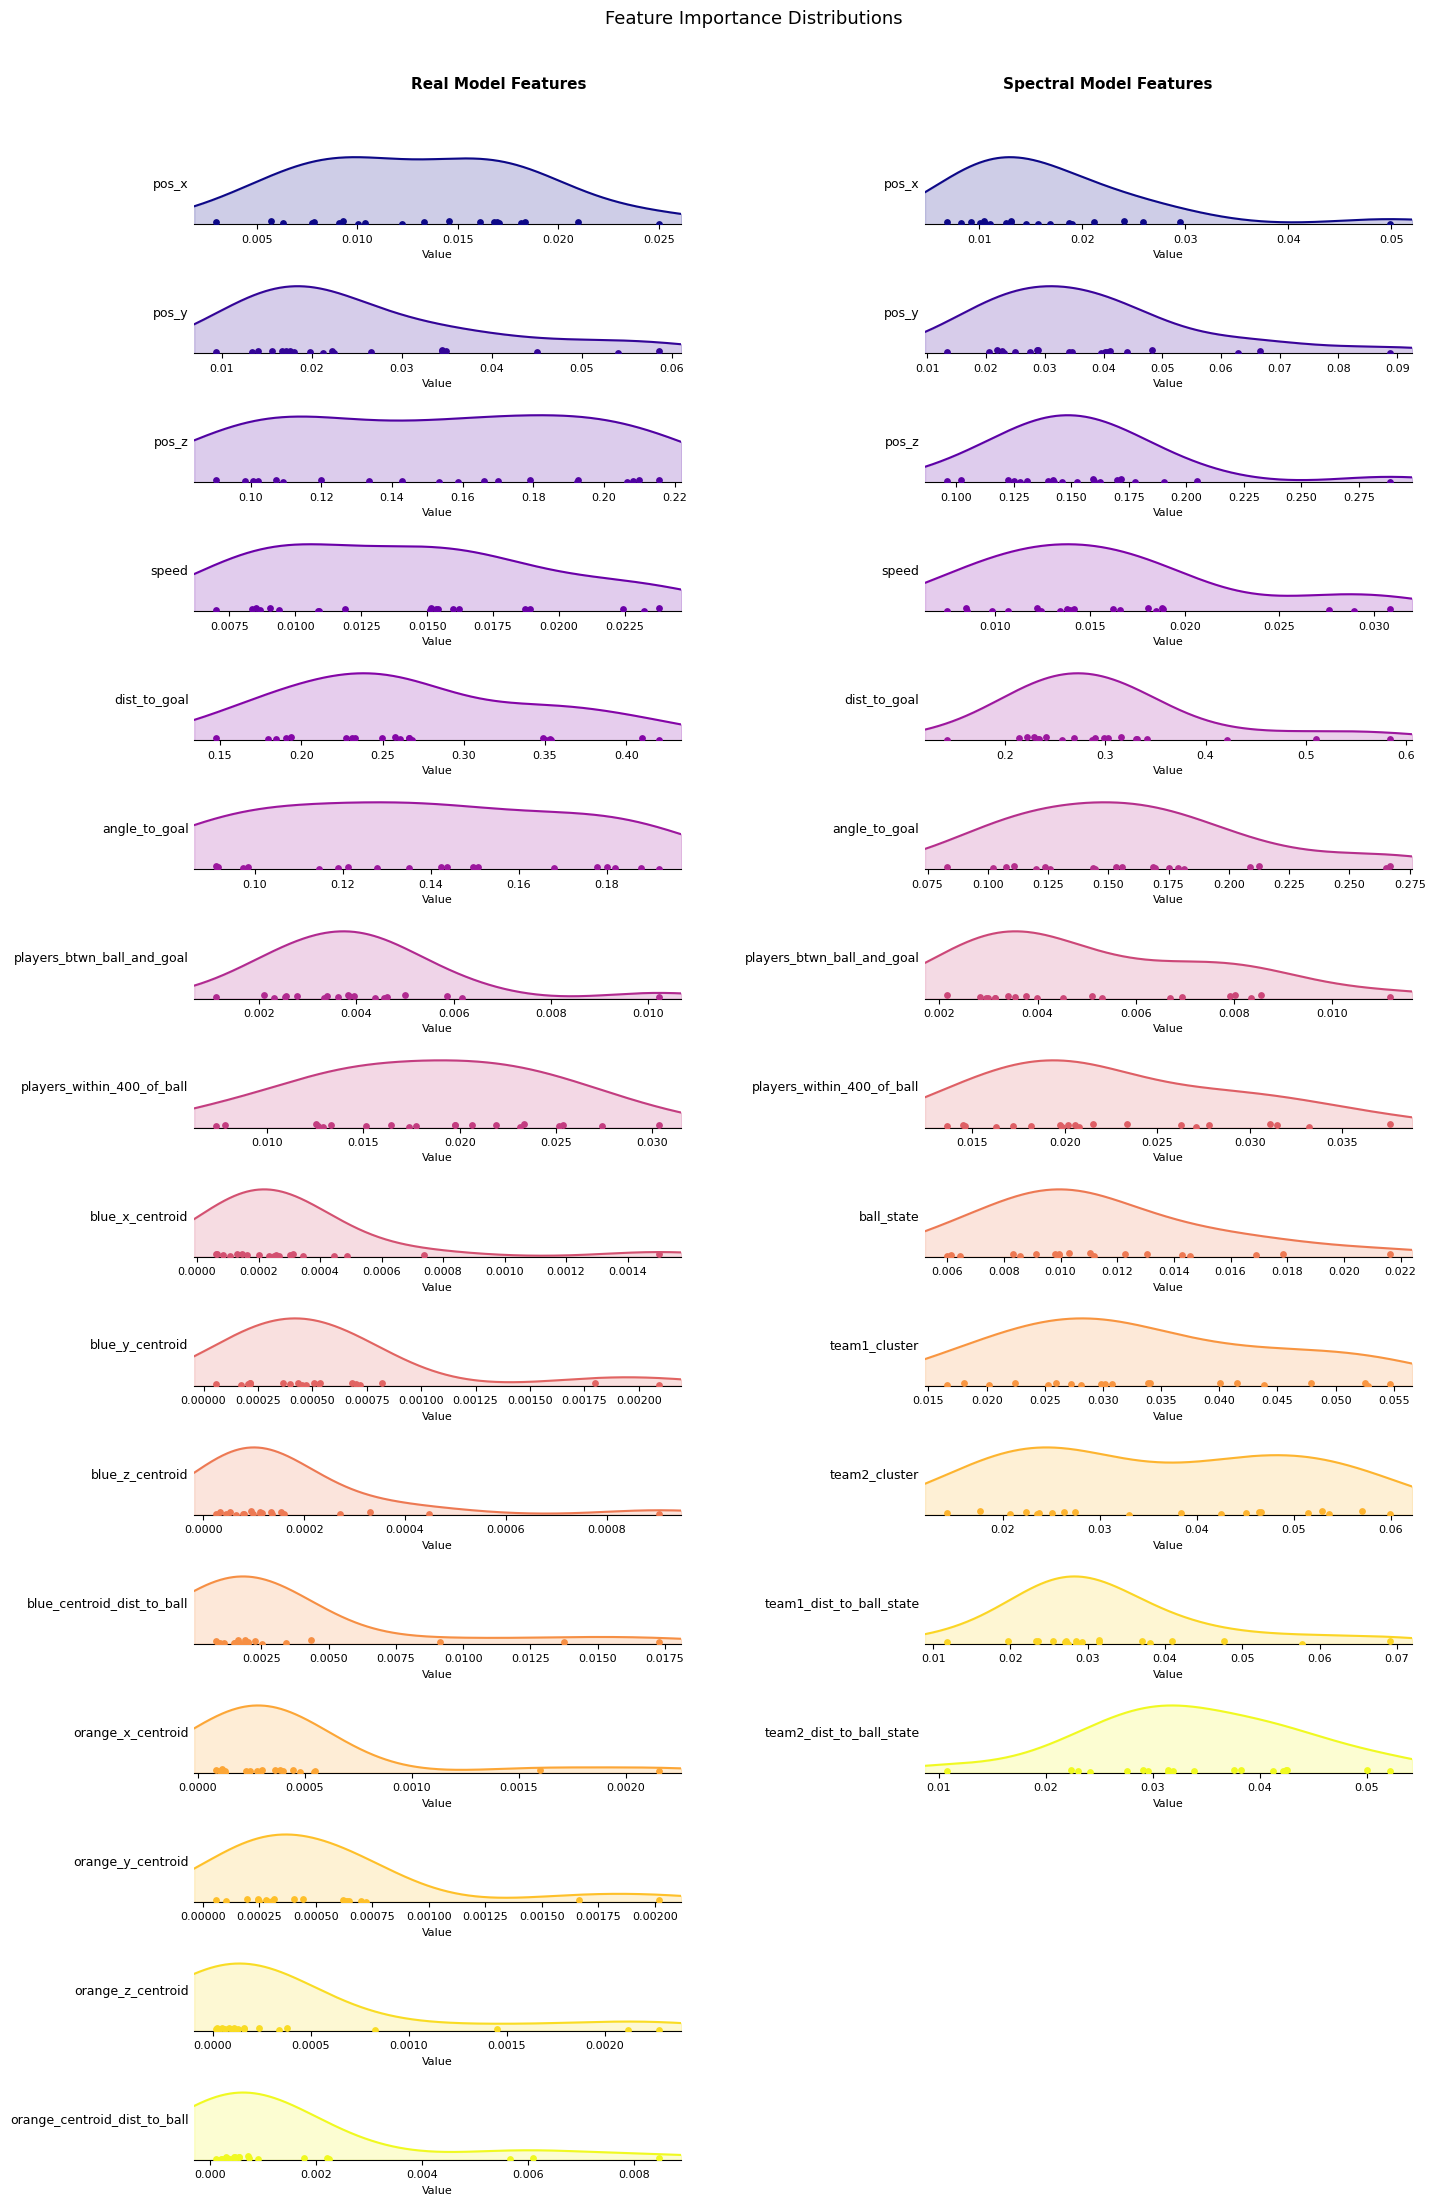

In [38]:
fig = ridgeplot2(
    real_feature_importances_df, spectral_feature_importances_df,
    figsize=(14, None),
    cmap='plasma',
    fill_alpha=0.2,
    point_alpha=1,
    col_titles=('Real Model Features', 'Spectral Model Features'),
    title='Feature Importance Distributions'
)
plt.show()

### <center>Statistical Tests to Compare Performance<center>

**Methodology:**
- When comparing the shared features, a simple "head to head" test will be done to see if they are equal
- When comparing the spectral features to their original counterpart, the spectral features will be compared to the sum of the original counterparts:
    - I.e., if there is no difference in performance, we expect the sum of the contributions to the model prediction of the original xyz features to be approximately equal to that of the single spectral feature that encodes the same data

#### Head to Head Comparison of Shared Features:

In [65]:
width = 100
col = width // 3

print(f"{'Model Comparison: Real vs Spectral Feature Importances':^{width}}")
print(f"{'Shared Features':^{width}}")
print(f"{'H_0: real = spectral':^{col}}|{'H_0: real <= spectral':^{col}}|{'H_0: real >= spectral':^{col}}")
print('-' * width)

for spec_feat, real_feat in zip(spectral_model_features[0:8], real_model_features[0:8]):
    test1 = stats.mannwhitneyu(x=real_feature_importances_df[real_feat],
                               y=spectral_feature_importances_df[spec_feat])
    test2 = stats.mannwhitneyu(x=real_feature_importances_df[real_feat],
                               y=spectral_feature_importances_df[spec_feat],
                               alternative='greater')
    test3 = stats.mannwhitneyu(x=real_feature_importances_df[real_feat],
                               y=spectral_feature_importances_df[spec_feat],
                               alternative='less')
    
    print(f"{spec_feat}")
    print(f"{f'p = {test1.pvalue:.4f}':^{col}}|{f'p = {test2.pvalue:.4f}':^{col}}|{f'p = {test3.pvalue:.4f}':^{col}}")
    print('-' * width)

                       Model Comparison: Real vs Spectral Feature Importances                       
                                          Shared Features                                           
      H_0: real = spectral       |      H_0: real <= spectral      |      H_0: real >= spectral      
----------------------------------------------------------------------------------------------------
pos_x
           p = 0.1806            |           p = 0.9140            |           p = 0.0903            
----------------------------------------------------------------------------------------------------
pos_y
           p = 0.0098            |           p = 0.9955            |           p = 0.0049            
----------------------------------------------------------------------------------------------------
pos_z
           p = 0.9246            |           p = 0.4623            |           p = 0.5484            
---------------------------------------------------------------------

The tests show that the two models are largely in agreement on feature importances, with a couple of notable exceptions. The most significant difference is in `pos_y`, where the spectral model assigns meaningfully higher importance than the real model (p = 0.0049). A similar pattern holds for `players_within_400_of_ball`, where the spectral model again weights the feature more heavily (p = 0.0339). There are also borderline signals for `pos_x` and `players_btwn_ball_and_goal`, though these fall just short when using $\alpha = 0.5$. For the remaining features (`pos_z`, `speed`, `dist_to_goal`, and `angle_to_goal`) the two models show no meaningful difference in how they weight those inputs. 

This suggests that for both models, the tests show that the features that are shared between the two models show similar impacts on predictions.

#### Comparison of Real Positional Features to Spectral Embeddings:

In [84]:
summed_blue_real_positions = real_feature_importances_df.iloc[:,8:11].sum(axis=1)
summed_orange_real_positions = real_feature_importances_df.iloc[:,12:15].sum(axis=1)
summed_ball_real_positions = real_feature_importances_df.iloc[:,0:3].sum(axis=1)

In [85]:
real_positional_features_vectors = [summed_blue_real_positions, summed_orange_real_positions, 
                                    real_feature_importances_df['blue_centroid_dist_to_ball'],
                                    real_feature_importances_df['orange_centroid_dist_to_ball'],
                                    summed_ball_real_positions]
spectral_positional_features_vectors = [spectral_feature_importances_df['team1_cluster'], 
                                        spectral_feature_importances_df['team2_cluster'],
                                        spectral_feature_importances_df['team1_dist_to_ball_state'],
                                        spectral_feature_importances_df['team2_dist_to_ball_state'],
                                        spectral_feature_importances_df['ball_state']]

real_positional_features = ['summed_blue_xyz', 'summed_orange_xyz', 
                            'blue_centroid_dist_to_ball', 'orange_centroid_dist_to_ball',
                            'summed_ball_xyz']
spectral_positional_features = ['team1_cluster', 'team2_cluster', 'team1_dist_to_ball_state',
                                'team2_dist_to_ball_state', 'ball_state']

In [86]:
width = 100
col = width // 3

print(f"{'Model Comparison: Real vs Spectral Feature Importances':^{width}}")
print(f"{'Real vs Spectral Embedding Features':^{width}}")
print(f"{'H_0: real = spectral':^{col}}|{'H_0: real <= spectral':^{col}}|{'H_0: real >= spectral':^{col}}")
print('-' * width)

for spec_feat_vec, real_feat_vec, real_feat_name, spec_feat_name in zip(spectral_positional_features_vectors, real_positional_features_vectors, real_positional_features, spectral_positional_features):
    test1 = stats.mannwhitneyu(x=real_feat_vec,
                               y=spec_feat_vec)
    test2 = stats.mannwhitneyu(x=real_feat_vec,
                               y=spec_feat_vec,
                               alternative='greater')
    test3 = stats.mannwhitneyu(x=real_feat_vec,
                               y=spec_feat_vec,
                               alternative='less')
    
    print(f"{real_feat_name} vs {spec_feat_name}")
    print(f"{f'p = {test1.pvalue:.4f}':^{col}}|{f'p = {test2.pvalue:.4f}':^{col}}|{f'p = {test3.pvalue:.4f}':^{col}}")
    print('-' * width)

                       Model Comparison: Real vs Spectral Feature Importances                       
                                Real vs Spectral Embedding Features                                 
      H_0: real = spectral       |      H_0: real <= spectral      |      H_0: real >= spectral      
----------------------------------------------------------------------------------------------------
summed_blue_xyz vs team1_cluster
           p = 0.0000            |           p = 1.0000            |           p = 0.0000            
----------------------------------------------------------------------------------------------------
summed_orange_xyz vs team2_cluster
           p = 0.0000            |           p = 1.0000            |           p = 0.0000            
----------------------------------------------------------------------------------------------------
blue_centroid_dist_to_ball vs team1_dist_to_ball_state
           p = 0.0000            |           p = 1.0000           

The tests show extreme significance that the spectral embeddings for the positional data of the teams/players are more informative for predictions than their 'real units' counterparts. 

An interesting result is the exact opposite result for the spectral embeding of the ball's positions, as its real counterparts are significantly more informative for predictions.

The results do seem to suggest that using a spectral for positional data in modeling sports outcomes create more informative features.